In [ ]:
import sys
import time
import importlib.util
from pathlib import Path

def find_project_root(start_path=None):
    if start_path is None:
        start_path = Path.cwd()
    else:
        start_path = Path(start_path)

    current = start_path.resolve()

    while True:
        if (current / "09_config.py").exists() and (current / "08_utils.py").exists():
            return current
        if current.parent == current:
            raise FileNotFoundError("Project root tidak ditemukan.")
        current = current.parent

def import_py_file(module_name, file_path):
    file_path = Path(file_path).resolve()
    spec = importlib.util.spec_from_file_location(module_name, file_path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[module_name] = module
    spec.loader.exec_module(module)
    return module

PROJECT_ROOT = find_project_root()
cfg = import_py_file("ferplus_config", PROJECT_ROOT / "09_config.py")
utils = import_py_file("ferplus_utils", PROJECT_ROOT / "08_utils.py")

utils.set_global_seed(cfg.SEED)
utils.ensure_directories()

print(cfg.SCENARIO_NOTES["model_3"])
print("Train dir:", cfg.TRAIN_FULL_DIR)
print("Validation dir:", cfg.VALIDATION_NON_AUGMENTED_DIR)
print("Test dir:", cfg.TEST_DIR)

TensorFlow op determinism: ENABLED
Model 3 menggunakan training_full yang sama persis dengan Model 2, augmentation tambahan yang sama persis dengan Model 2, lalu dilanjutkan dengan fine-tuning sebagian layer atas EfficientNetB0.
Train dir: C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset\training_full
Validation dir: C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset\validation_non_augmented
Test dir: C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset\test


In [2]:
train_ds, validation_ds, test_ds = utils.load_datasets_for_scenario("model_3")

for images, labels in train_ds.take(1):
    print("Batch image shape:", images.shape)
    print("Batch label shape:", labels.shape)
    print("Pixel min:", images.numpy().min())
    print("Pixel max:", images.numpy().max())
    print("Contoh label:", labels.numpy()[:10])

Found 66379 files belonging to 8 classes.
Found 3579 files belonging to 8 classes.
Found 3573 files belonging to 8 classes.
Batch image shape: (32, 224, 224, 3)
Batch label shape: (32,)
Pixel min: 0.0
Pixel max: 255.0
Contoh label: [5 5 7 0 2 1 1 1 2 0]


In [3]:
model_3 = utils.build_efficientnetb0_model(
    model_name=cfg.MODEL_3_NAME,
    use_augmentation=True,
    base_trainable=False,
    learning_rate=cfg.LEARNING_RATE_HEAD
)

model_3.summary()


TensorFlow op determinism: ENABLED


Model: "model_3_training_full_augmentation_finetuning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_head (Dense)     │ (None, 8)              │        10,248 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,059,819 (15.49 MB)

 Trainable params: 10,248 (40.03 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
callbacks_phase_1 = utils.get_callbacks(
    run_name=cfg.MODEL_3_PHASE_1_NAME,
    checkpoint_path=cfg.MODEL_3_PHASE_1_BEST_PATH,
    monitor="val_accuracy"
)

phase_1_start_time = time.time()

history_3_phase_1 = model_3.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=cfg.EPOCHS_MODEL_3_HEAD,
    callbacks=callbacks_phase_1,
    verbose=1
)

phase_1_duration = time.time() - phase_1_start_time

phase_1_time_info = {
    "model": cfg.MODEL_3_PHASE_1_NAME,
    "scenario": "Model 3 phase 1 head training",
    "train_dir": str(cfg.TRAIN_FULL_DIR),
    "validation_dir": str(cfg.VALIDATION_NON_AUGMENTED_DIR),
    "duration_seconds": phase_1_duration,
    "duration_formatted": utils.format_seconds(phase_1_duration)
}

phase_1_time_path = (
    cfg.LOG_DIR / f"{cfg.MODEL_3_PHASE_1_NAME}_training_time.json"
)

utils.save_json(phase_1_time_info, phase_1_time_path)

print("Best checkpoint tahap 1:", cfg.MODEL_3_PHASE_1_BEST_PATH)
print("Waktu training tahap 1:", utils.format_seconds(phase_1_duration))

Epoch 1/30
2075/2075 ━━━━━━━━━━━━━━━━━━━━ 0s 422ms/step - accuracy: 0.4339 - loss: 1.5345
Epoch 1: val_accuracy improved from -inf to 0.62476, saving model to C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\models\model_3_phase_1_head_training_best.keras
2075/2075 ━━━━━━━━━━━━━━━━━━━━ 915s 435ms/step - accuracy: 0.4340 - loss: 1.5345 - val_accuracy: 0.6248 - val_loss: 1.1114 - learning_rate: 0.0010
Epoch 2/30
2075/2075 ━━━━━━━━━━━━━━━━━━━━ 0s 284ms/step - accuracy: 0.5483 - loss: 1.2418
Epoch 2: val_accuracy improved from 0.62476 to 0.63677, saving model to C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\models\model_3_phase_1_head_training_best.keras
2075/2075 ━━━━━━━━━━━━━━━━━━━━ 618s 298ms/step - accuracy: 0.5483 - loss: 1.2418 - val_accuracy: 0.6368 - val_loss: 1.0635 - learning_rate: 0.0010
Epoch 3/30
2075/2075 ━━━━━━━━━━━━━━━━━━━━ 0s 270ms/step - accuracy: 0.5628 - loss: 1.2058
Epoch 3: val_accuracy improved from 0.63677 to 0.63761, saving model to C:\Users\Davi

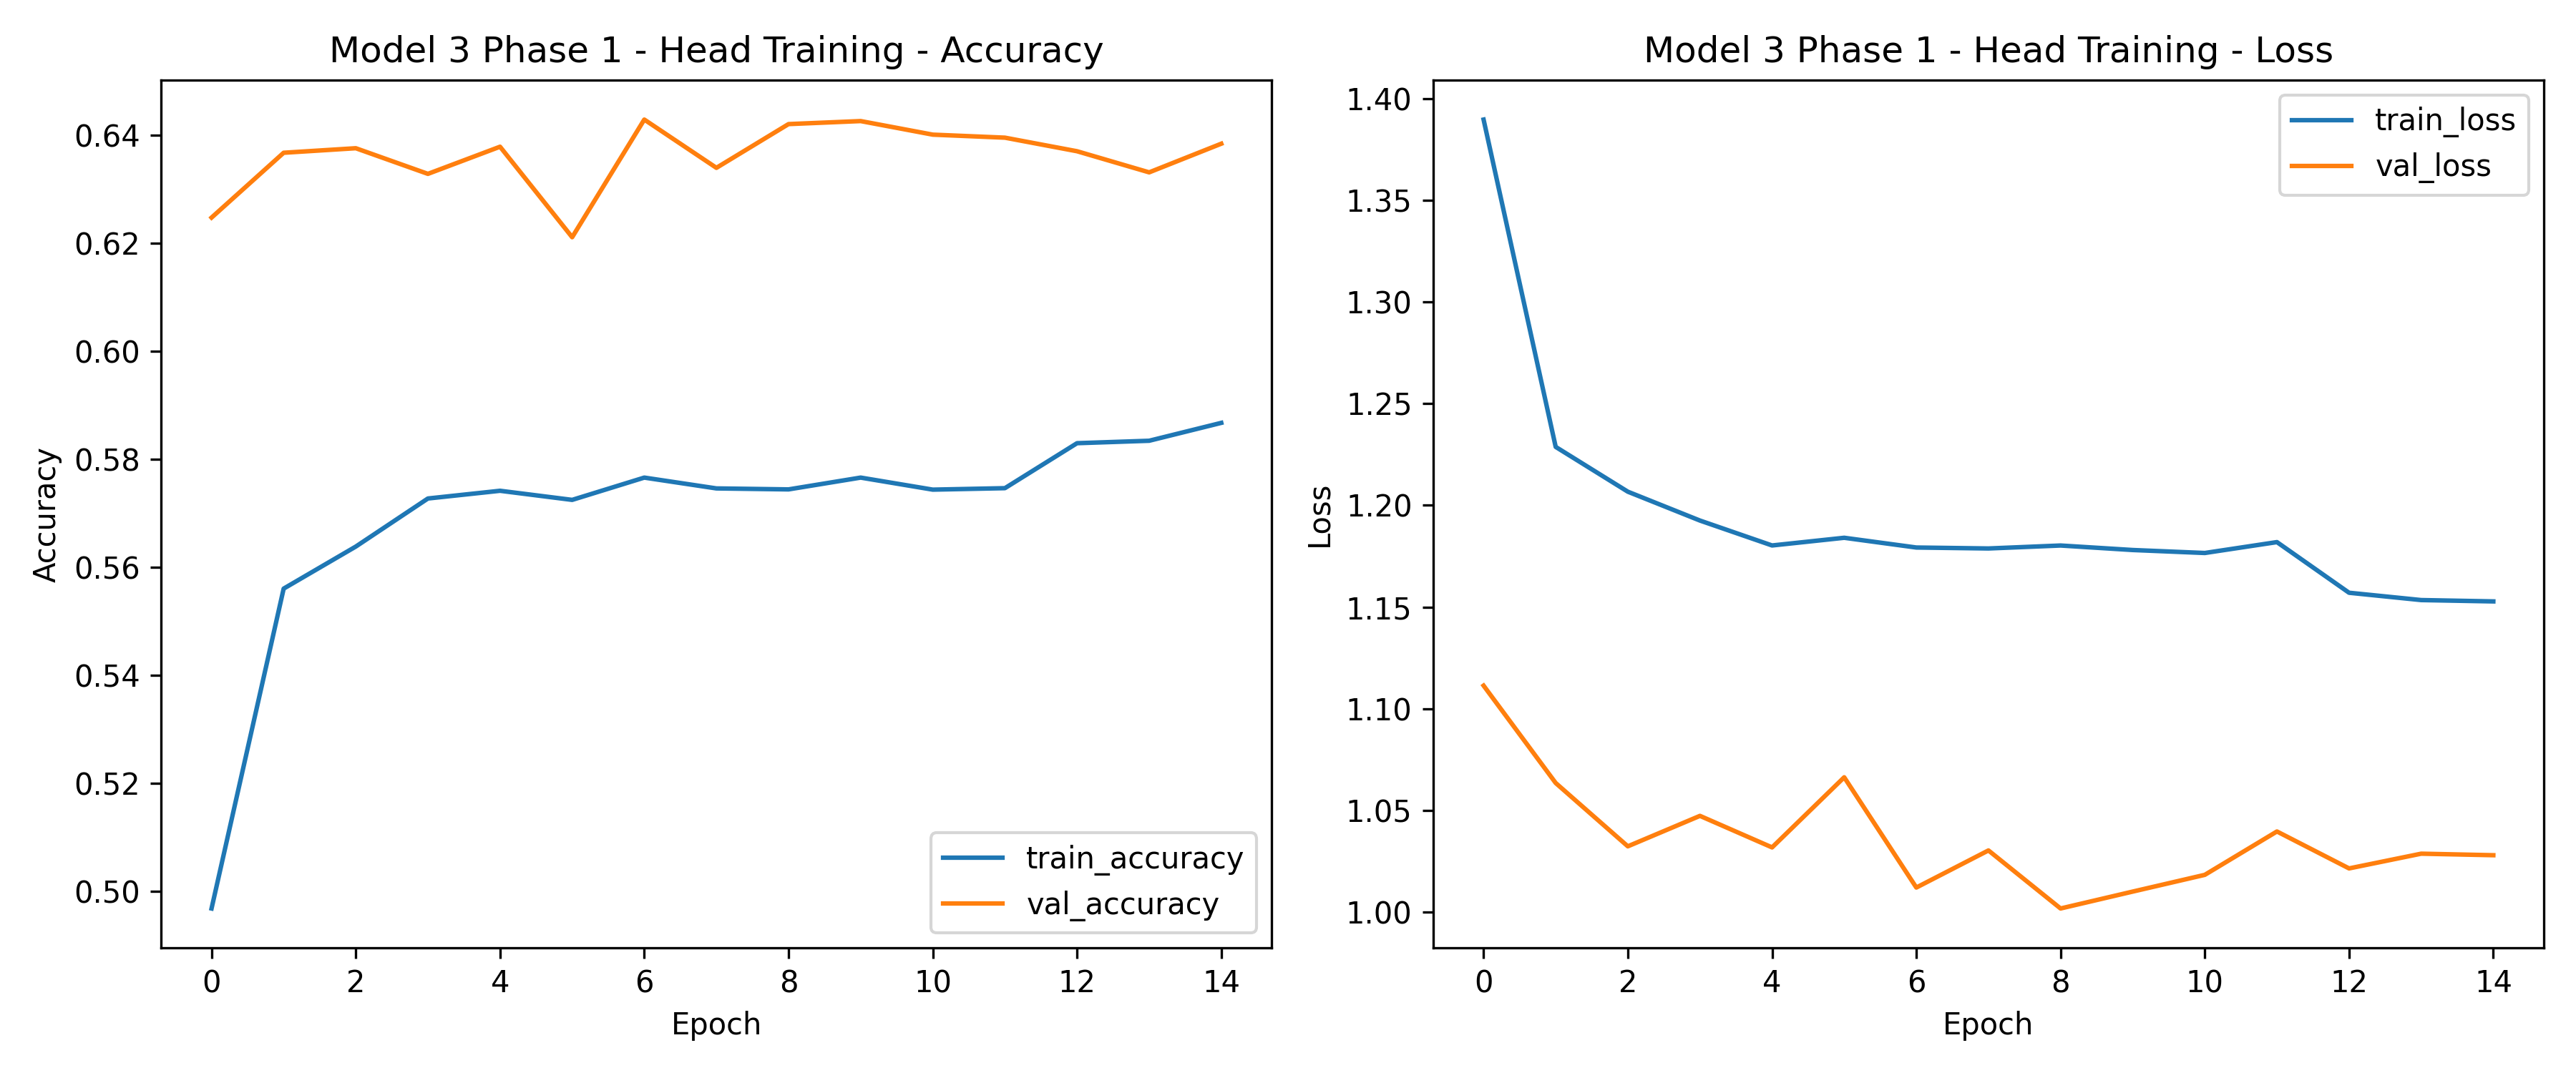

Grafik tahap 1 disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\figures\training_history_model_3_phase_1_head_training.png


In [ ]:
phase_1_fig_path = cfg.FIGURE_DIR / "training_history_model_3_phase_1_head_training.png"

utils.plot_training_history(
    history=history_3_phase_1,
    title="Model 3 Phase 1 - Head Training",
    save_path=phase_1_fig_path
)

print("Grafik tahap 1 disimpan ke:", phase_1_fig_path)

In [ ]:
import tensorflow as tf

model_3 = tf.keras.models.load_model (cfg.MODEL_3_PHASE_1_BEST_PATH)

model_3 = utils.prepare_model_for_fine_tuning(
    model=model_3,
    last_n_layers=cfg.FINE_TUNE_LAST_N_LAYERS
)

model_3.summary()

Model: "model_3_training_full_augmentation_finetuning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_head (Dense)     │ (None, 8)              │        10,248 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,059,819 (15.49 MB)

 Trainable params: 2,518,936 (9.61 MB)

 Non-trainable params: 1,540,883 (5.88 MB)

In [ ]:
callbacks_fine_tune = utils.get_callbacks(
    run_name=cfg.MODEL_3_NAME,
    checkpoint_path=cfg.MODEL_3_BEST_PATH,
    monitor="val_accuracy"
)

phase_2_start_time = time.time()

history_3_fine_tune = model_3.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=cfg.EPOCHS_MODEL_3_FINE_TUNE,
    callbacks=callbacks_fine_tune,
    verbose=1
)

phase_2_duration = time.time() - phase_2_start_time

total_duration = phase_1_duration + phase_2_duration

phase_2_time_info = {
    "model": cfg.MODEL_3_NAME,
    "scenario": "Model 3 phase 2 fine tuning",
    "train_dir": str(cfg.TRAIN_FULL_DIR),
    "validation_dir": str(cfg.VALIDATION_NON_AUGMENTED_DIR),
    "fine_tune_last_n_layers": cfg.FINE_TUNE_LAST_N_LAYERS,
    "learning_rate_fine_tune": cfg.LEARNING_RATE_FINE_TUNE,
    "phase_1_duration_seconds": phase_1_duration,
    "phase_2_duration_seconds": phase_2_duration,
    "total_duration_seconds": total_duration,
    "phase_1_duration_formatted": utils.format_seconds(phase_1_duration),
    "phase_2_duration_formatted": utils.format_seconds(phase_2_duration),
    "total_duration_formatted": utils.format_seconds(total_duration)
}

phase_2_time_path = cfg.LOG_DIR / f"{cfg.MODEL_3_NAME}_training_time.json"
utils.save_json(phase_2_time_info, phase_2_time_path)

print("Best checkpoint Model 3:", cfg.MODEL_3_BEST_PATH)
print("Waktu fine-tuning:", utils.format_seconds(phase_2_duration))
print("Total waktu Model 3:", utils.format_seconds(total_duration))

Epoch 1/30
2075/2075 ━━━━━━━━━━━━━━━━━━━━ 0s 326ms/step - accuracy: 0.6101 - loss: 1.0799
Epoch 1: val_accuracy improved from -inf to 0.68902, saving model to C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\models\model_3_training_full_augmentation_finetuning_best.keras
2075/2075 ━━━━━━━━━━━━━━━━━━━━ 712s 339ms/step - accuracy: 0.6101 - loss: 1.0799 - val_accuracy: 0.6890 - val_loss: 0.8697 - learning_rate: 1.0000e-05
Epoch 2/30
2075/2075 ━━━━━━━━━━━━━━━━━━━━ 0s 326ms/step - accuracy: 0.6778 - loss: 0.9011
Epoch 2: val_accuracy improved from 0.68902 to 0.71193, saving model to C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\models\model_3_training_full_augmentation_finetuning_best.keras
2075/2075 ━━━━━━━━━━━━━━━━━━━━ 703s 339ms/step - accuracy: 0.6778 - loss: 0.9011 - val_accuracy: 0.7119 - val_loss: 0.8143 - learning_rate: 1.0000e-05
Epoch 3/30
2075/2075 ━━━━━━━━━━━━━━━━━━━━ 0s 331ms/step - accuracy: 0.7124 - loss: 0.8016
Epoch 3: val_accuracy improved from 0.71193 t

Best model: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\models\model_3_training_full_augmentation_finetuning_best.keras
Final model: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\models\model_3_training_full_augmentation_finetuning_final.keras


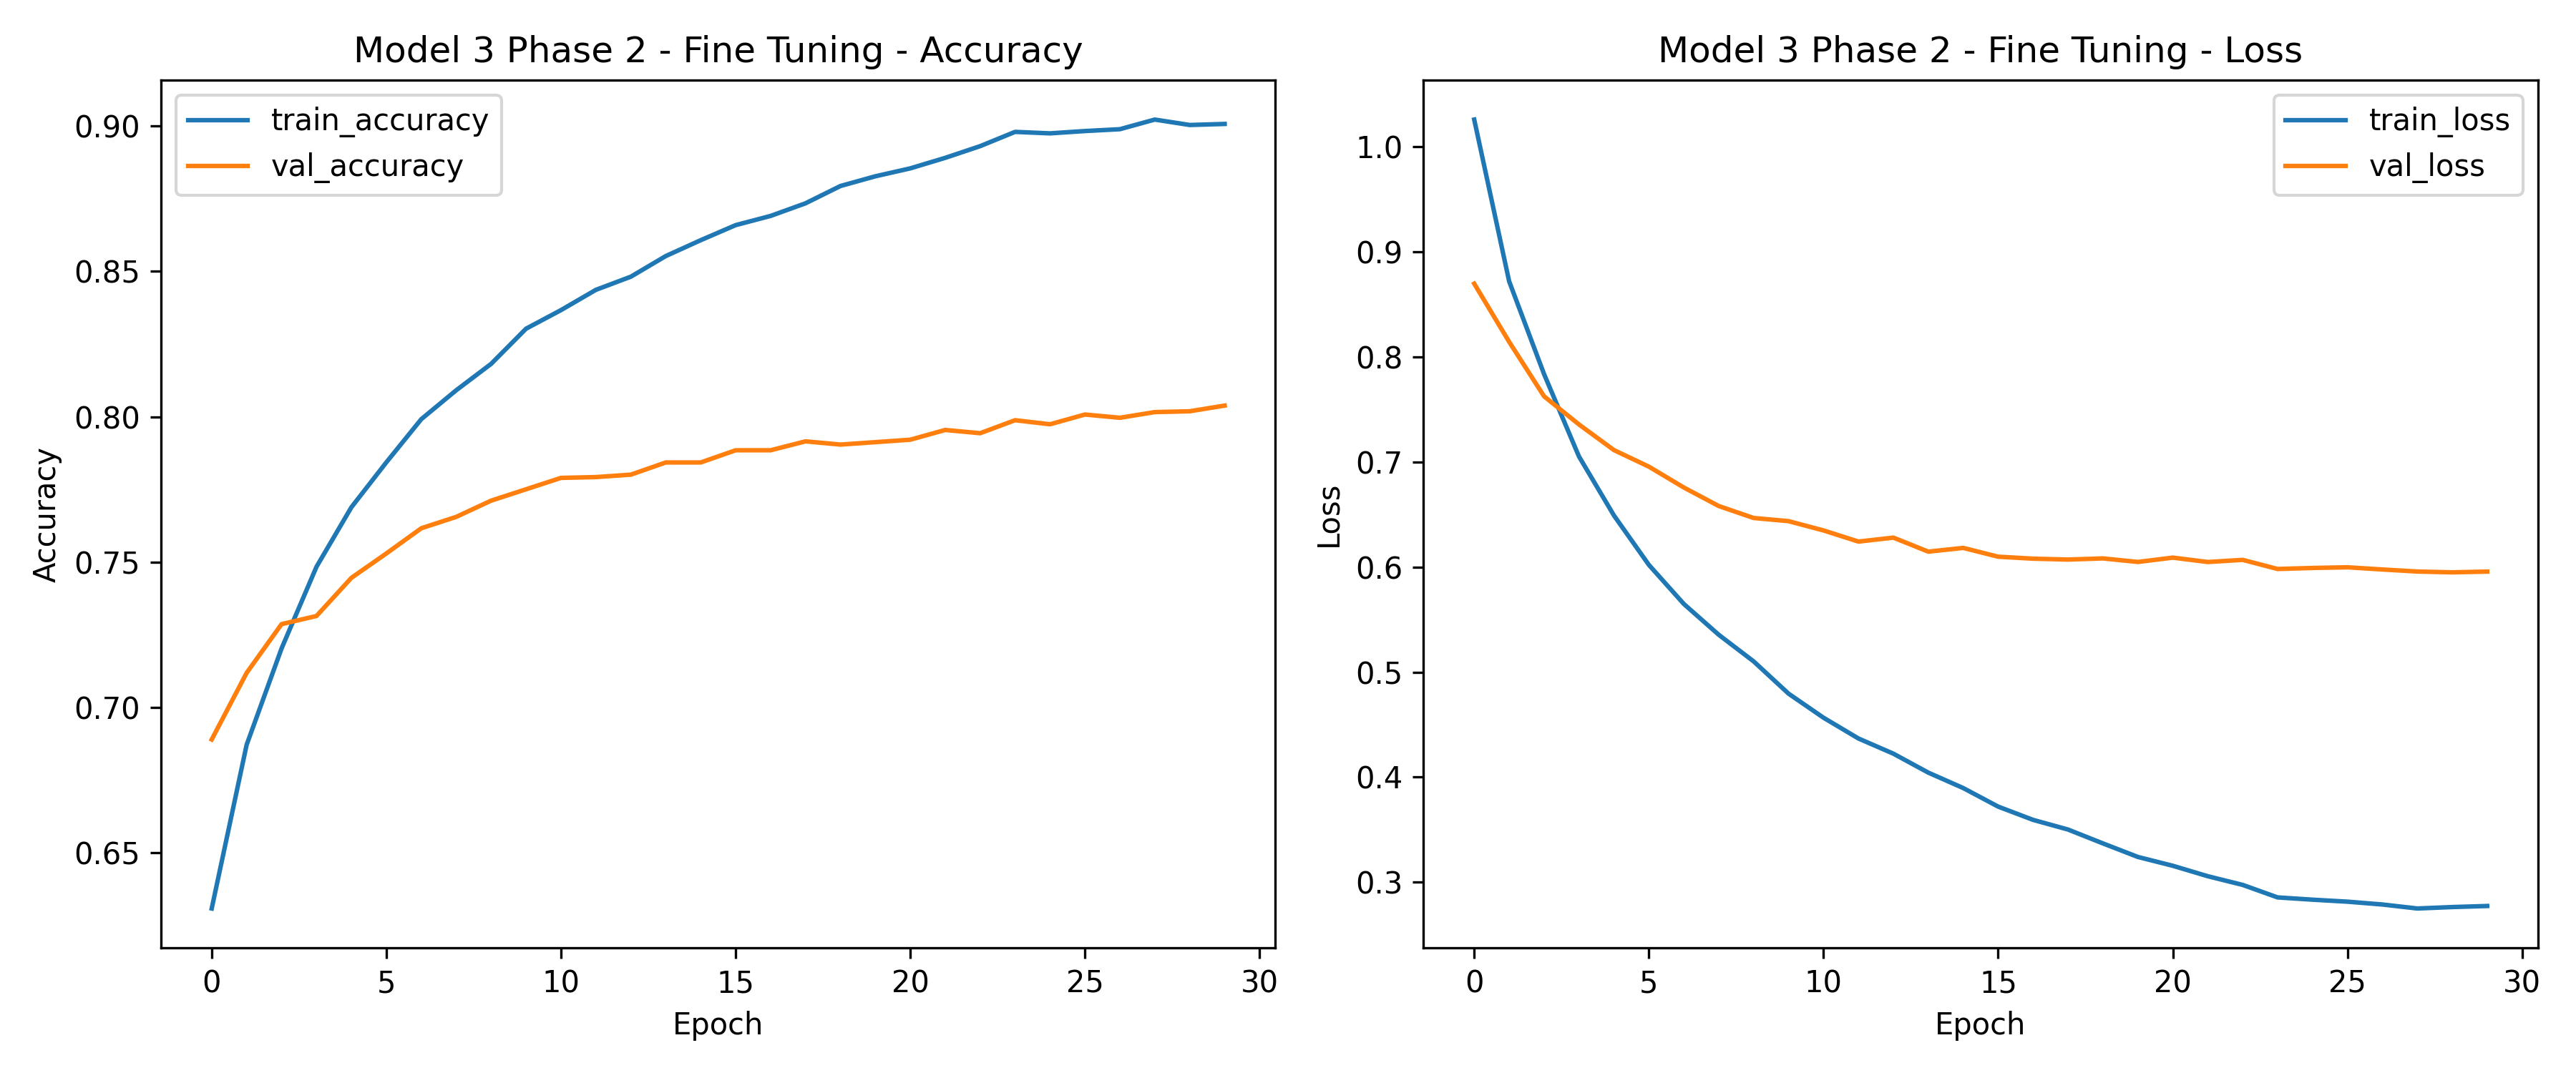

Grafik fine-tuning disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\figures\training_history_model_3_fine_tuning.png


In [ ]:
model_3.save(cfg.MODEL_3_FINAL_PATH)

print("Best model:", cfg.MODEL_3_BEST_PATH)
print("Final model:", cfg.MODEL_3_FINAL_PATH)

phase_2_fig_path = cfg.FIGURE_DIR / "training_history_model_3_fine_tuning.png"

utils.plot_training_history(
    history=history_3_fine_tune,
    title="Model 3 Phase 2 - Fine Tuning",
    save_path=phase_2_fig_path
)

print("Grafik fine-tuning disimpan ke:", phase_2_fig_path)

In [10]:
val_loss, val_accuracy = model_3.evaluate(validation_ds, verbose=1)

print("Validation loss:", val_loss)
print("Validation accuracy:", val_accuracy)

112/112 ━━━━━━━━━━━━━━━━━━━━ 37s 332ms/step - accuracy: 0.7834 - loss: 0.7201
Validation loss: 0.595663845539093
Validation accuracy: 0.803855836391449
